#Predicción del tipo de parto mediante técnicas de Machine Learning a partir de características maternas, paternas y del nacimiento en Bucaramanga


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

sns.set_theme()
pd.__version__

'2.2.3'

## 1. Cargar el archivo desde Google Drive

In [2]:
import gdown

file_id = '1_Xri3ALFFf8T0yviS6nWWRQ5uSfSbH0w'
url = f'https://drive.google.com/uc?id={file_id}'

# Descarga el archivo al entorno local de Colab
gdown.download(url, 'nacidos_vivos.csv', quiet=False)

# Lo lees directamente desde el disco virtual de Colab
a = pd.read_csv('nacidos_vivos.csv', low_memory=False)
print(type(a))
a.head()

Downloading...
From: https://drive.google.com/uc?id=1_Xri3ALFFf8T0yviS6nWWRQ5uSfSbH0w
To: /content/nacidos_vivos.csv
100%|██████████| 18.0M/18.0M [00:00<00:00, 78.5MB/s]


<class 'pandas.core.frame.DataFrame'>


,DEPARTAMENTO,MUNICIPIO,AREA NACIMIENTO,SITIO NACIMIENTO,SEXO,PESO (Gramos),TALLA (Centímetros),PARTO ATENDIDO POR,NUMERO CONSULTAS PRENATALES,TIPO PARTO,...,departamento_residencia,AREA RESIDENCIA,LOCALIDAD,CENTRO POBLADO,NÚMERO HIJOS NACIDOS VIVOS,NÚMERO EMBARAZOS,RÉGIMEN SEGURIDAD,EDAD PADRE,NIVEL EDUCATIVO PADRE,ULTIMO AÑO APROBADO PADRE
0,SANTANDER,BUCARAMANGA,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,MASCULINO,2420,49,MÉDICO,4,ESPONTÁNEO,...,SANTANDER,CABECERA MUNICIPAL,NO RESPONDE,NO RESPONDE,1,1,SUBSIDIADO,26,BÁSICA PRIMARIA,5
1,SANTANDER,BUCARAMANGA,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,FEMENINO,3340,51,MÉDICO,3,ESPONTÁNEO,...,SANTANDER,CABECERA MUNICIPAL,NO RESPONDE,NO RESPONDE,1,1,CONTRIBUTIVO,20,MEDIA ACADÉMICA O CLÁSICA,11
2,SANTANDER,BUCARAMANGA,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,MASCULINO,2580,46,MÉDICO,4,ESPONTÁNEO,...,SANTANDER,CABECERA MUNICIPAL,NO RESPONDE,NO RESPONDE,1,2,CONTRIBUTIVO,30,MAESTRÍA,3
3,SANTANDER,BUCARAMANGA,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,FEMENINO,3300,51,MÉDICO,10,ESPONTÁNEO,...,SANTANDER,CABECERA MUNICIPAL,NO RESPONDE,NO RESPONDE,2,2,CONTRIBUTIVO,38,ESPECIALIZACIÓN,2
4,SANTANDER,BUCARAMANGA,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,FEMENINO,3030,50,MÉDICO,9,ESPONTÁNEO,...,SANTANDER,CABECERA MUNICIPAL,NO RESPONDE,NO RESPONDE,1,1,CONTRIBUTIVO,31,MEDIA ACADÉMICA O CLÁSICA,11


In [3]:
# Nombres de todas las columnas (aquí ya se ven los nombres con codificación rota)
a.columns

Index(['DEPARTAMENTO', 'MUNICIPIO', 'AREA NACIMIENTO', 'SITIO NACIMIENTO',
       'SEXO', 'PESO (Gramos)', 'TALLA (Centímetros)', 'PARTO ATENDIDO POR',
       'NUMERO CONSULTAS PRENATALES', 'TIPO PARTO', 'MULTIPLICIDAD EMBARAZO',
       'APGAR1', 'APGAR2', 'GRUPO SANGUINEO', 'FACTOR RH', 'GRUPO INDIGENA',
       'EDAD MADRE', 'NIVEL EDUCATIVO MADRE', 'ULTIMO AÑO APROBADO MADRE',
       'PAIS RESIDENCIA', 'departamento_residencia', 'AREA RESIDENCIA',
       'LOCALIDAD', 'CENTRO POBLADO', 'NÚMERO HIJOS NACIDOS VIVOS',
       'NÚMERO EMBARAZOS', 'RÉGIMEN SEGURIDAD', 'EDAD PADRE',
       'NIVEL EDUCATIVO PADRE', 'ULTIMO AÑO APROBADO PADRE'],
      dtype='object')

## 2. Corregir la codificación de texto (columnas y valores)


In [4]:
def fix_mojibake(texto):
    """Revierte tildes/Ñ corrompidas (ej. 'MEDELL√çN' -> 'MEDELLÍN')."""
    if isinstance(texto, str) and '√' in texto:
        try:
            return texto.encode('mac_roman').decode('utf-8')
        except (UnicodeDecodeError, UnicodeEncodeError):
            return texto
    return texto

# 2.1 Nombres de columnas
a.columns = [fix_mojibake(c) for c in a.columns]

# 2.2 Valores de texto en cada columna categórica
columnas_texto = a.select_dtypes(include='object').columns
for c in columnas_texto:
    a[c] = a[c].map(fix_mojibake)

a.columns.tolist()

['DEPARTAMENTO',
 'MUNICIPIO',
 'AREA NACIMIENTO',
 'SITIO NACIMIENTO',
 'SEXO',
 'PESO (Gramos)',
 'TALLA (Centímetros)',
 'PARTO ATENDIDO POR',
 'NUMERO CONSULTAS PRENATALES',
 'TIPO PARTO',
 'MULTIPLICIDAD EMBARAZO',
 'APGAR1',
 'APGAR2',
 'GRUPO SANGUINEO',
 'FACTOR RH',
 'GRUPO INDIGENA',
 'EDAD MADRE',
 'NIVEL EDUCATIVO MADRE',
 'ULTIMO AÑO APROBADO MADRE',
 'PAIS RESIDENCIA',
 'departamento_residencia',
 'AREA RESIDENCIA',
 'LOCALIDAD',
 'CENTRO POBLADO',
 'NÚMERO HIJOS NACIDOS VIVOS',
 'NÚMERO EMBARAZOS',
 'RÉGIMEN SEGURIDAD',
 'EDAD PADRE',
 'NIVEL EDUCATIVO PADRE',
 'ULTIMO AÑO APROBADO PADRE']

In [5]:
# Tipos de datos, memoria y valores nulos
a.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66555 entries, 0 to 66554
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   DEPARTAMENTO                 66555 non-null  object
 1   MUNICIPIO                    66555 non-null  object
 2   AREA NACIMIENTO              66555 non-null  object
 3   SITIO NACIMIENTO             66555 non-null  object
 4   SEXO                         66555 non-null  object
 5   PESO (Gramos)                66555 non-null  object
 6   TALLA (Centímetros)          66555 non-null  object
 7   PARTO ATENDIDO POR           66555 non-null  object
 8   NUMERO CONSULTAS PRENATALES  66555 non-null  object
 9   TIPO PARTO                   66555 non-null  object
 10  MULTIPLICIDAD EMBARAZO       66555 non-null  object
 11  APGAR1                       66555 non-null  object
 12  APGAR2                       66555 non-null  object
 13  GRUPO SANGUINEO              66

In [6]:
# Resumen estadístico (media, desviación, cuartiles, min, max)
a.describe()

,EDAD MADRE,NÚMERO HIJOS NACIDOS VIVOS
count,66555.000000,66555.000000
mean,26.817324,1.798738
std,6.375296,0.991680
min,11.000000,1.000000
25%,22.000000,1.000000
50%,26.000000,2.000000
75%,31.000000,2.000000
max,53.000000,20.000000


## 3. Convertir a numéricas las columnas que corresponden


In [7]:
columnas_numericas = [
    'PESO (Gramos)',
    'TALLA (Centímetros)',
    'NUMERO CONSULTAS PRENATALES',
    'APGAR1',
    'APGAR2',
    'EDAD MADRE',
    'ULTIMO AÑO APROBADO MADRE',
    'NÚMERO HIJOS NACIDOS VIVOS',
    'NÚMERO EMBARAZOS',
    'EDAD PADRE',
    'ULTIMO AÑO APROBADO PADRE'
]

for col in columnas_numericas:
    a[col] = pd.to_numeric(a[col], errors='coerce')

a[columnas_numericas].dtypes

,0
PESO (Gramos),float64
TALLA (Centímetros),float64
NUMERO CONSULTAS PRENATALES,float64
APGAR1,float64
APGAR2,float64
EDAD MADRE,int64
ULTIMO AÑO APROBADO MADRE,float64
NÚMERO HIJOS NACIDOS VIVOS,int64
NÚMERO EMBARAZOS,float64
EDAD PADRE,float64


## 4. Outliers con IQR

In [8]:
resultados = []
for col in columnas_numericas:
    serie = a[col].dropna()

    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1

    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    outliers = serie[(serie < lim_inf) | (serie > lim_sup)]

    resultados.append({
        'Columna': col,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Límite Inferior': round(lim_inf, 2),
        'Límite Superior': round(lim_sup, 2),
        'Outliers': len(outliers),
        '% Outliers': round((len(outliers) / len(serie)) * 100, 2)
    })

a_iqr_resumen = pd.DataFrame(resultados)
a_iqr_resumen

,Columna,Q1,Q3,IQR,Límite Inferior,Límite Superior,Outliers,% Outliers
0,PESO (Gramos),2870.0,3455.0,585.0,1992.5,4332.5,2075,3.12
1,TALLA (Centímetros),49.0,52.0,3.0,44.5,56.5,2859,4.30
2,NUMERO CONSULTAS PRENATALES,5.0,8.0,3.0,0.5,12.5,1945,2.92
3,APGAR1,8.0,8.0,0.0,8.0,8.0,17682,26.59
4,APGAR2,9.0,10.0,1.0,7.5,11.5,951,1.43
5,EDAD MADRE,22.0,31.0,9.0,8.5,44.5,106,0.16
6,ULTIMO AÑO APROBADO MADRE,5.0,11.0,6.0,-4.0,20.0,0,0.00
7,NÚMERO HIJOS NACIDOS VIVOS,1.0,2.0,1.0,-0.5,3.5,3620,5.44
8,NÚMERO EMBARAZOS,1.0,3.0,2.0,-2.0,6.0,357,0.64
9,EDAD PADRE,25.0,35.0,10.0,10.0,50.0,836,1.26


## 5. Columnas categóricas

In [9]:
columnas_categoricas = [c for c in a.columns if c not in columnas_numericas]
print(f"Columnas categóricas ({len(columnas_categoricas)}):")
columnas_categoricas

Columnas categóricas (19):


['DEPARTAMENTO',
 'MUNICIPIO',
 'AREA NACIMIENTO',
 'SITIO NACIMIENTO',
 'SEXO',
 'PARTO ATENDIDO POR',
 'TIPO PARTO',
 'MULTIPLICIDAD EMBARAZO',
 'GRUPO SANGUINEO',
 'FACTOR RH',
 'GRUPO INDIGENA',
 'NIVEL EDUCATIVO MADRE',
 'PAIS RESIDENCIA',
 'departamento_residencia',
 'AREA RESIDENCIA',
 'LOCALIDAD',
 'CENTRO POBLADO',
 'RÉGIMEN SEGURIDAD',
 'NIVEL EDUCATIVO PADRE']

In [10]:
encoders = {}
for col in columnas_categoricas:
    le = LabelEncoder()
    valores = a[col].astype(str).fillna('SIN DATO')
    a[col + '_encoded'] = le.fit_transform(valores)
    encoders[col] = le

# vista rápida de las nuevas columnas numéricas
a.filter(like='_encoded').head()

,DEPARTAMENTO_encoded,MUNICIPIO_encoded,AREA NACIMIENTO_encoded,SITIO NACIMIENTO_encoded,SEXO_encoded,PARTO ATENDIDO POR_encoded,TIPO PARTO_encoded,MULTIPLICIDAD EMBARAZO_encoded,GRUPO SANGUINEO_encoded,FACTOR RH_encoded,GRUPO INDIGENA_encoded,NIVEL EDUCATIVO MADRE_encoded,PAIS RESIDENCIA_encoded,departamento_residencia_encoded,AREA RESIDENCIA_encoded,LOCALIDAD_encoded,CENTRO POBLADO_encoded,RÉGIMEN SEGURIDAD_encoded,NIVEL EDUCATIVO PADRE_encoded
0,8,4,0,1,2,3,1,2,2,2,6,0,1,16,0,12,49,4,0
1,8,4,0,1,0,3,1,2,4,2,6,5,1,16,0,12,49,0,5
2,8,4,0,1,2,3,1,2,1,2,6,3,1,16,0,12,49,0,4
3,8,4,0,1,0,3,1,2,4,2,6,10,1,16,0,12,49,0,3
4,8,4,0,1,0,3,1,2,4,0,6,5,1,16,0,12,49,0,5


## 6. Gráficas circulares para las variables categóricas

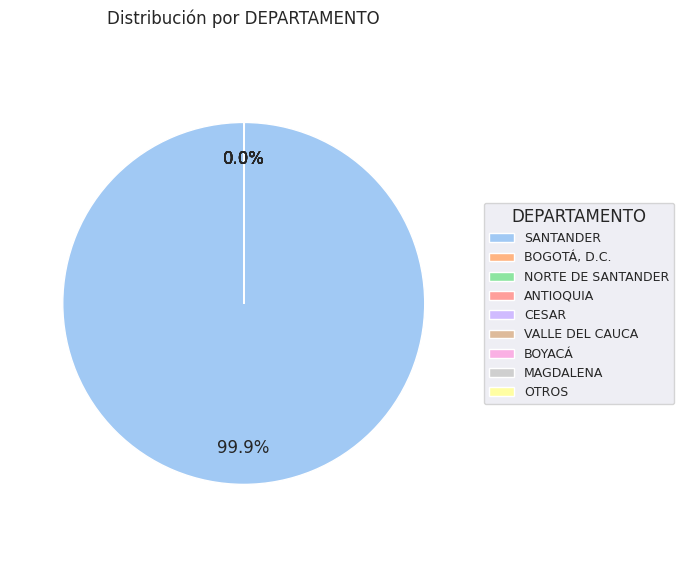

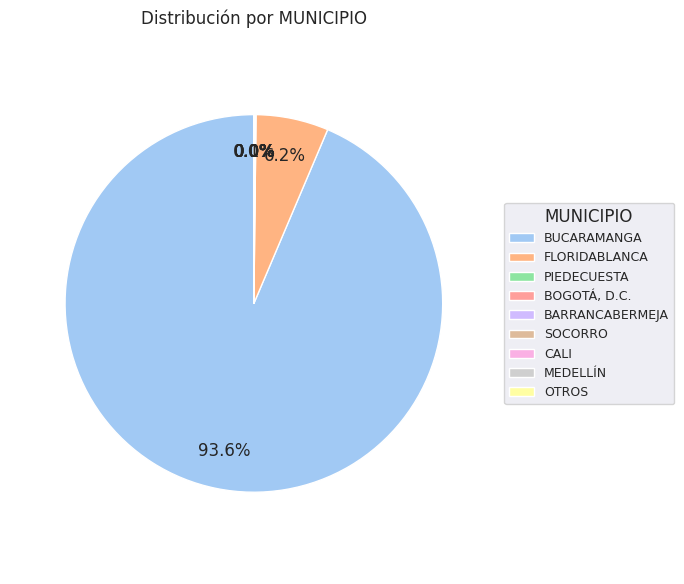

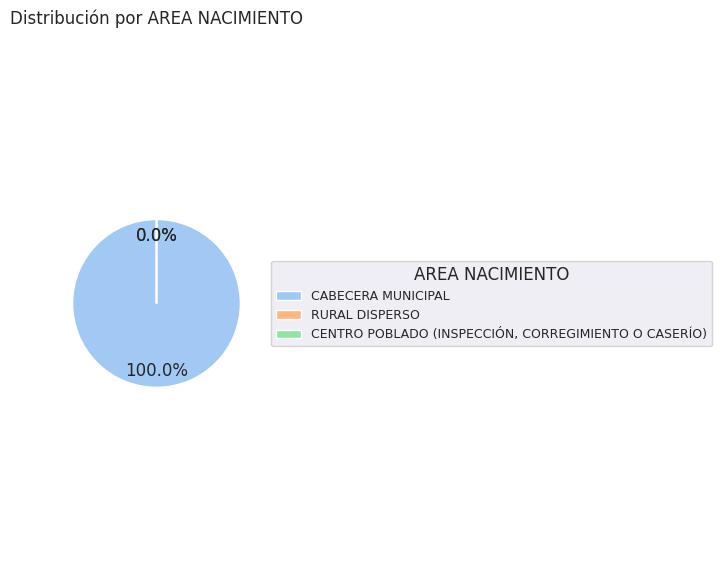

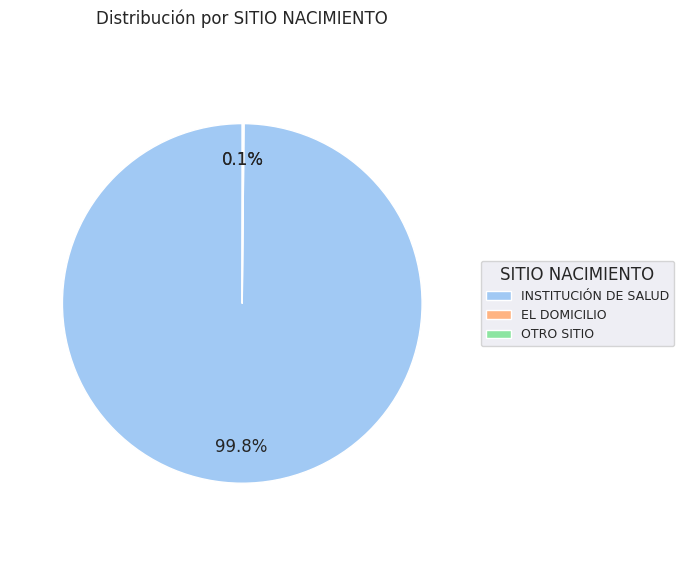

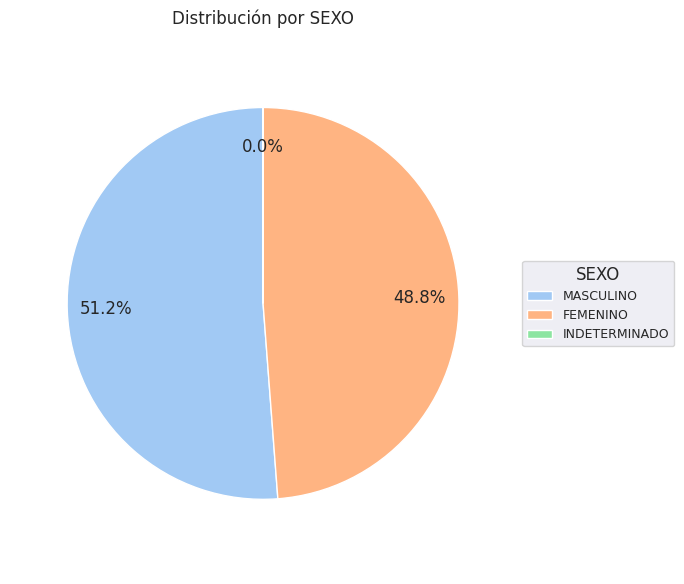

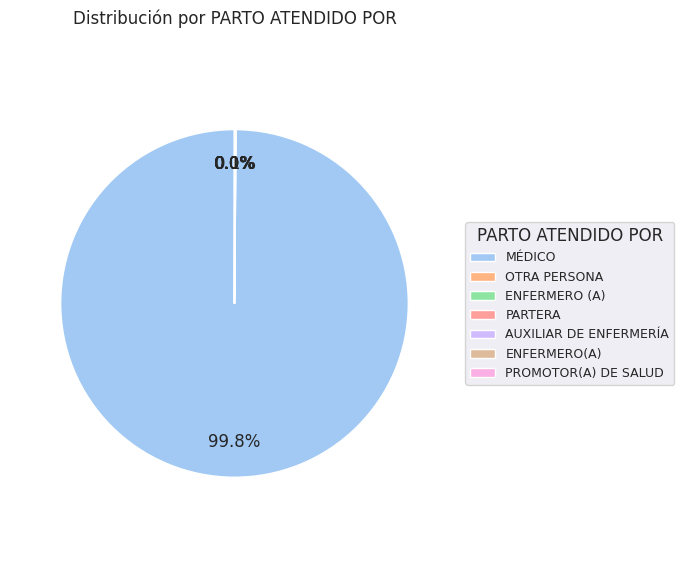

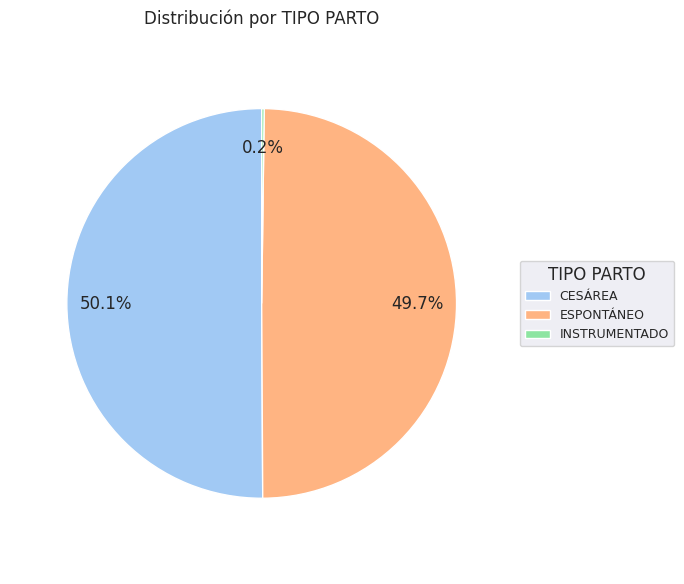

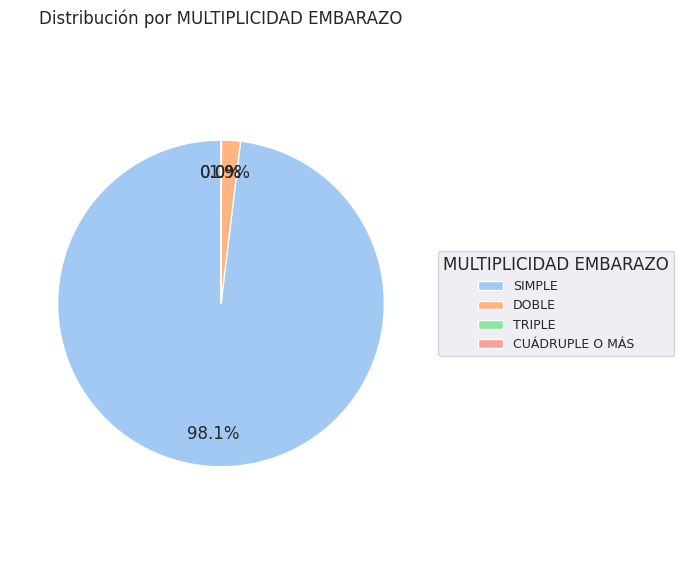

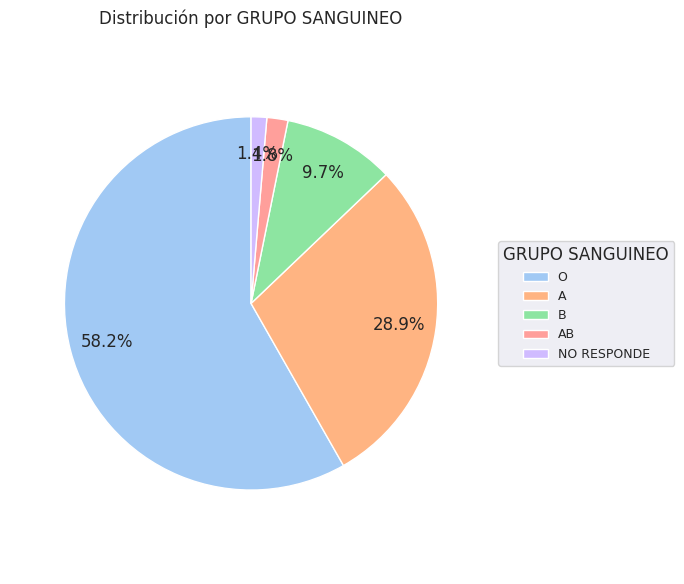

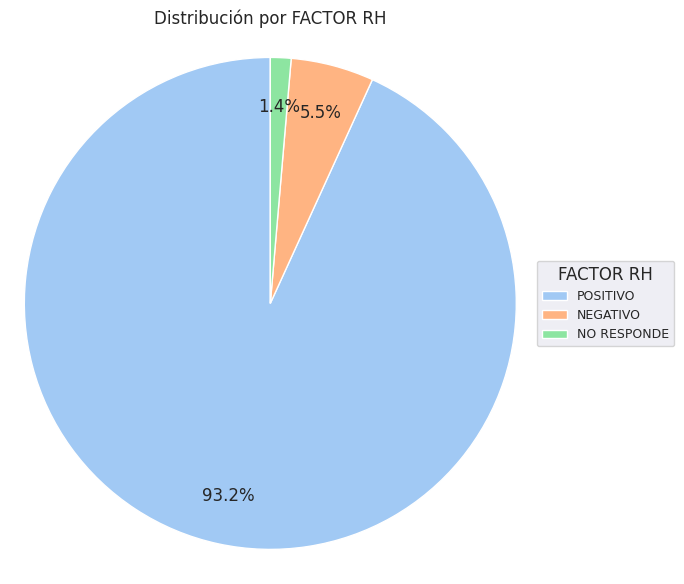

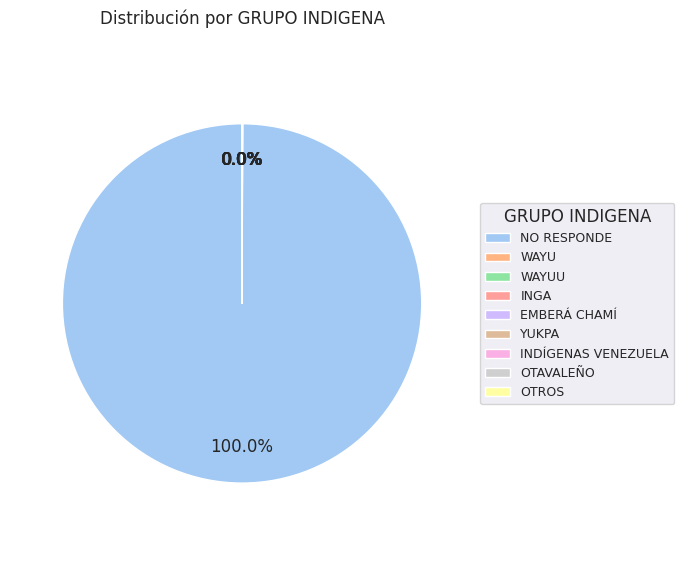

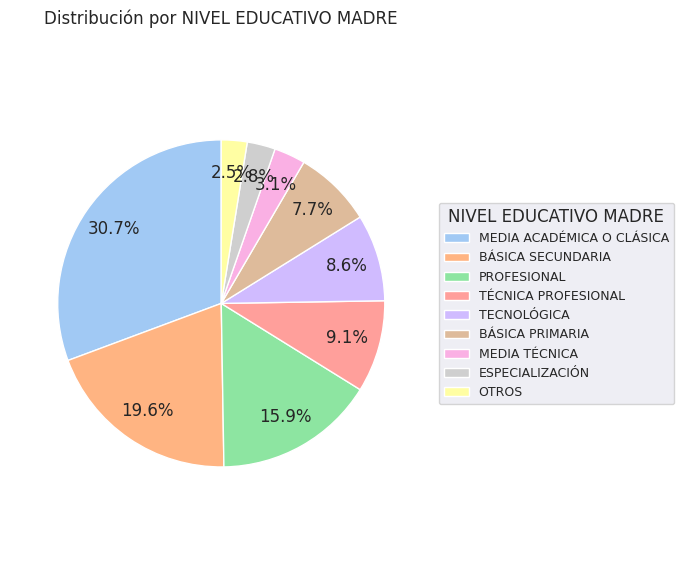

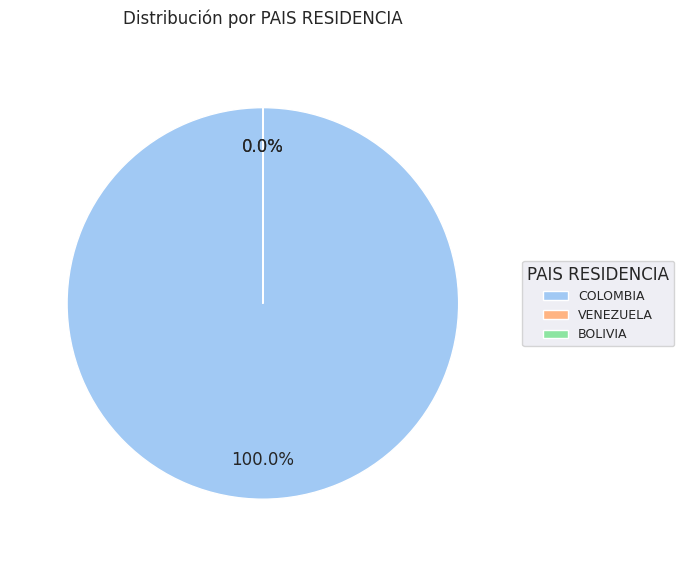

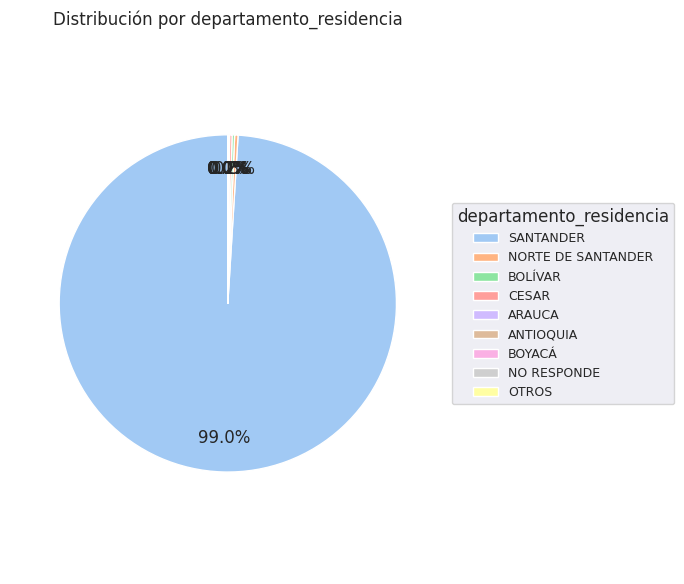

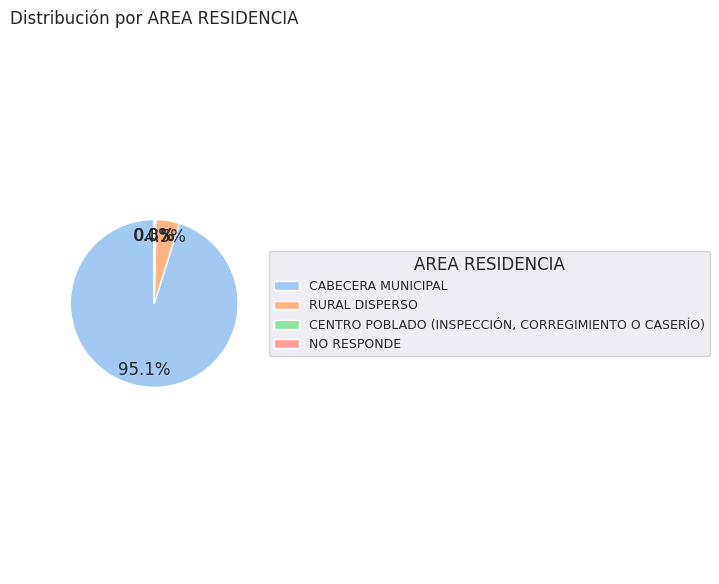

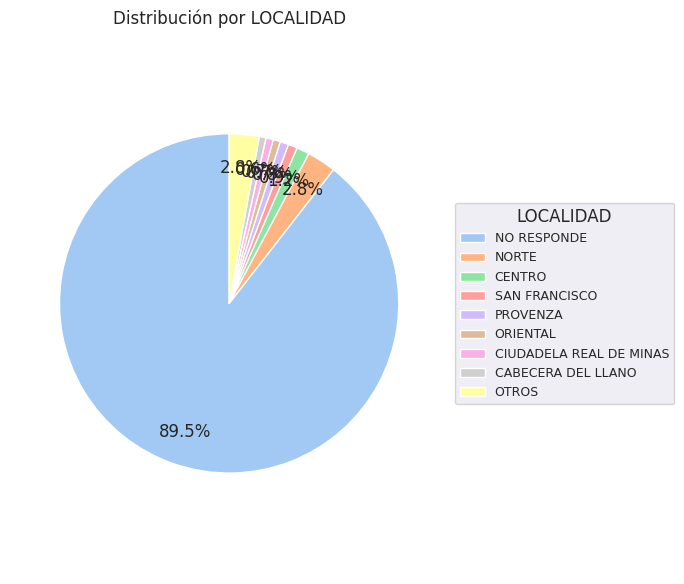

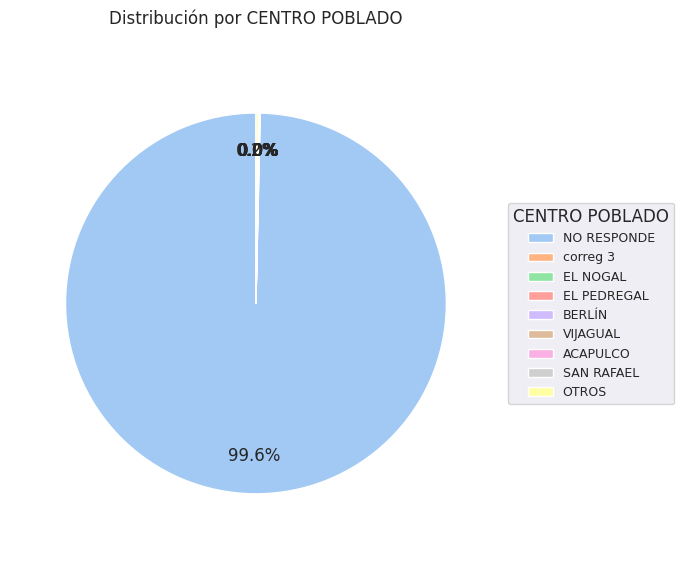

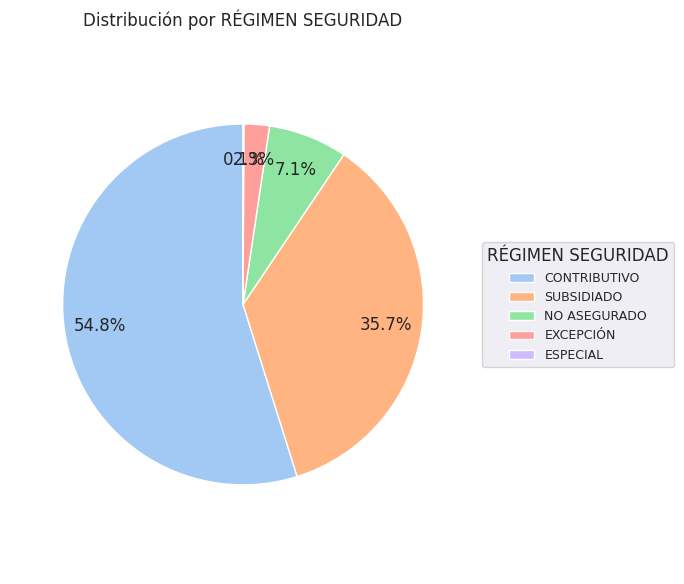

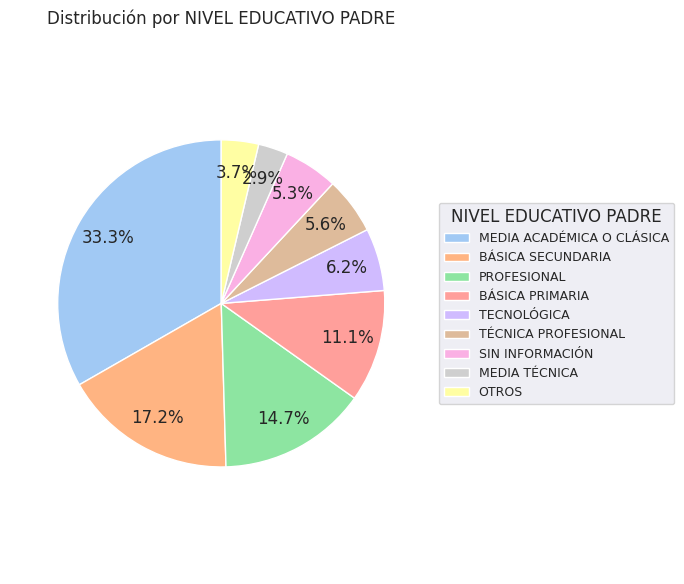

In [11]:
def graficar_pie(df, col, top_n=8):
    conteo = df[col].value_counts()
    if len(conteo) > top_n:
        top = conteo.iloc[:top_n]
        otros = conteo.iloc[top_n:].sum()
        conteo = pd.concat([top, pd.Series({'OTROS': otros})])

    plt.figure(figsize=(7, 6))
    wedges, _, _ = plt.pie(
        conteo,
        autopct='%1.1f%%',
        startangle=90,
        pctdistance=0.8,
        colors=sns.color_palette('pastel', len(conteo))
    )
    plt.legend(wedges, conteo.index, title=col, loc='center left', bbox_to_anchor=(1, 0.5), fontsize=9)
    plt.title(f'Distribución por {col}')
    plt.axis('equal')
    plt.tight_layout()
    plt.show()

for col in columnas_categoricas:
    graficar_pie(a, col)

## 7. Gráficas de líneas para las variables numéricas


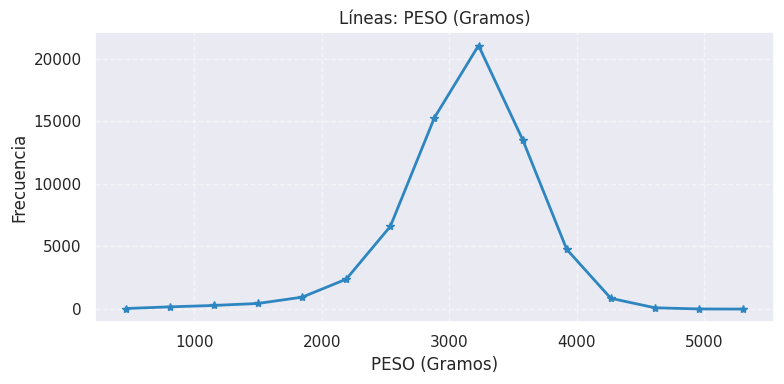

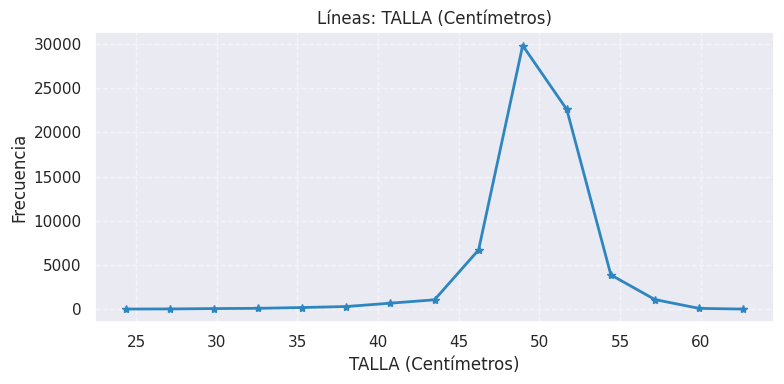

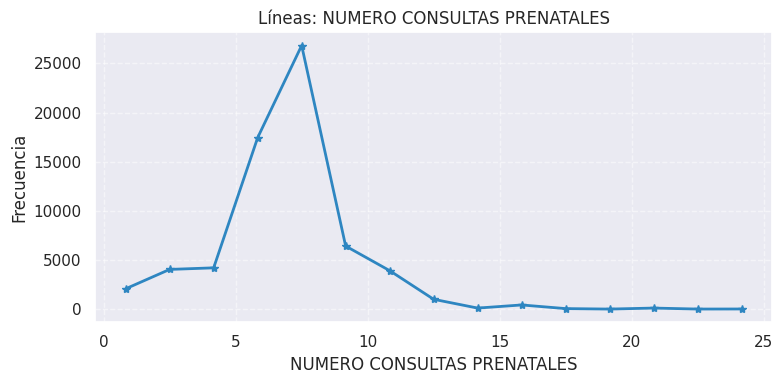

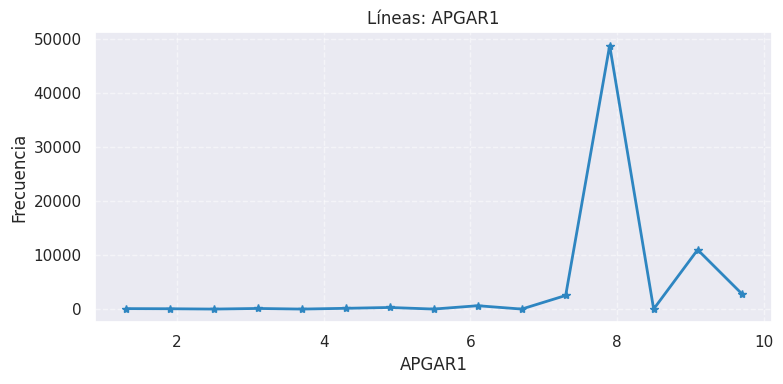

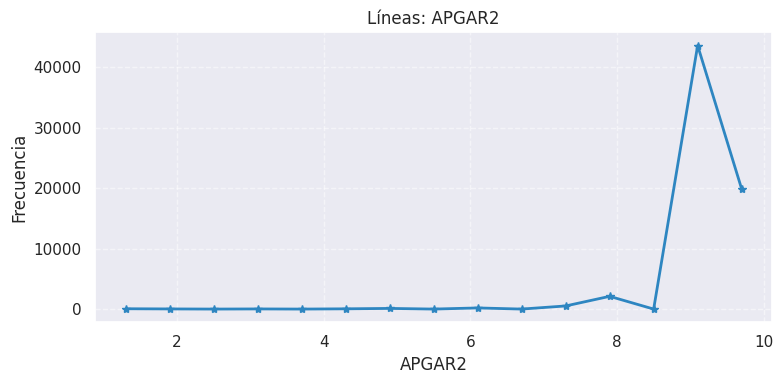

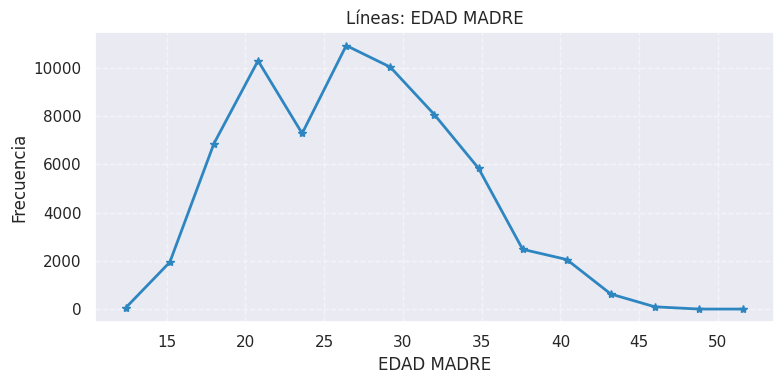

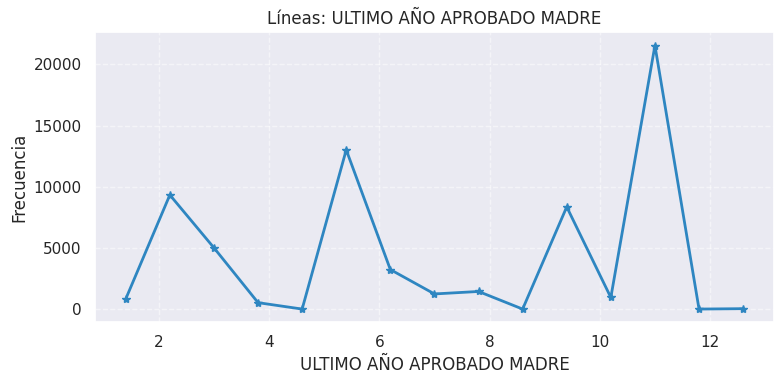

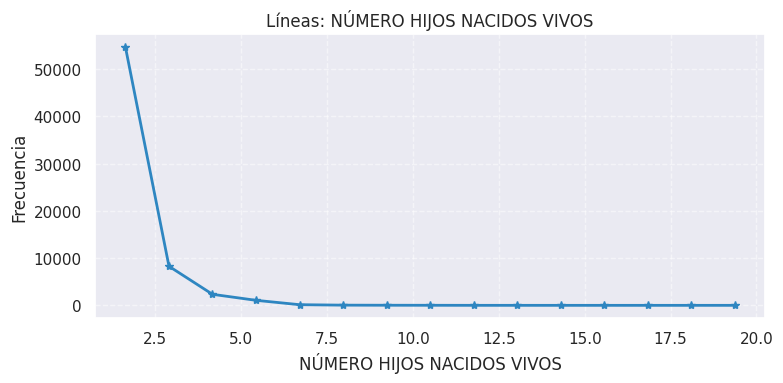

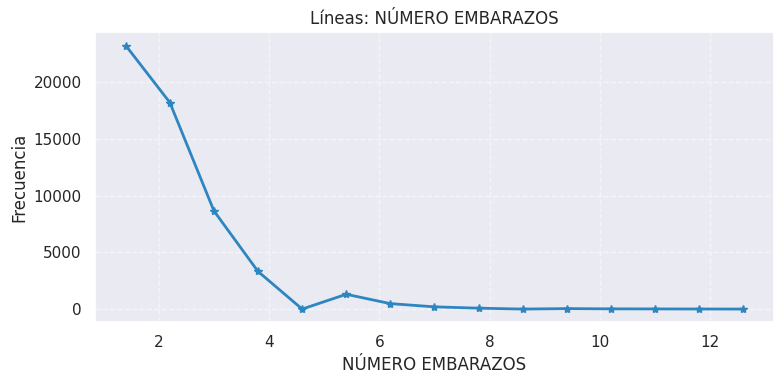

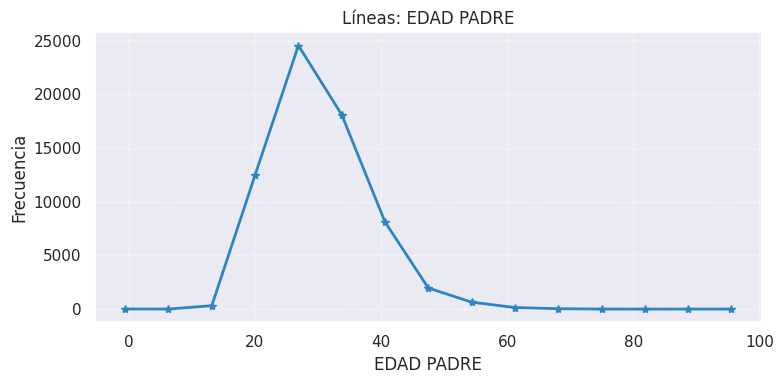

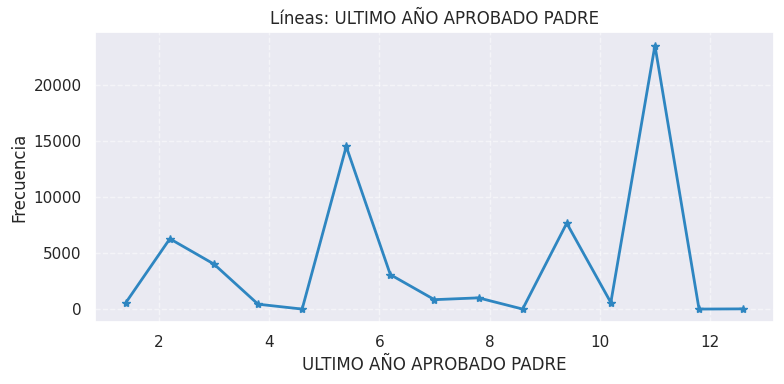

In [12]:
def graficar_numerica(df, col, bins=15):
    serie = df[col].dropna()

    conteos, bordes = np.histogram(serie, bins=bins)
    centros = (bordes[:-1] + bordes[1:]) / 2

    plt.figure(figsize=(8, 4))
    plt.plot(centros, conteos, marker='*', color='#2E86C1', linewidth=2)
    plt.title(f'Líneas: {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

for col in columnas_numericas:
    graficar_numerica(a, col)

## 8. Verificación final de columnas numéricas

In [13]:
columnas_numericas_final = a.select_dtypes(include='number').columns.tolist()
print("Columnas numéricas disponibles en el DataFrame final:")
columnas_numericas_final

Columnas numéricas disponibles en el DataFrame final:


['PESO (Gramos)',
 'TALLA (Centímetros)',
 'NUMERO CONSULTAS PRENATALES',
 'APGAR1',
 'APGAR2',
 'EDAD MADRE',
 'ULTIMO AÑO APROBADO MADRE',
 'NÚMERO HIJOS NACIDOS VIVOS',
 'NÚMERO EMBARAZOS',
 'EDAD PADRE',
 'ULTIMO AÑO APROBADO PADRE',
 'DEPARTAMENTO_encoded',
 'MUNICIPIO_encoded',
 'AREA NACIMIENTO_encoded',
 'SITIO NACIMIENTO_encoded',
 'SEXO_encoded',
 'PARTO ATENDIDO POR_encoded',
 'TIPO PARTO_encoded',
 'MULTIPLICIDAD EMBARAZO_encoded',
 'GRUPO SANGUINEO_encoded',
 'FACTOR RH_encoded',
 'GRUPO INDIGENA_encoded',
 'NIVEL EDUCATIVO MADRE_encoded',
 'PAIS RESIDENCIA_encoded',
 'departamento_residencia_encoded',
 'AREA RESIDENCIA_encoded',
 'LOCALIDAD_encoded',
 'CENTRO POBLADO_encoded',
 'RÉGIMEN SEGURIDAD_encoded',
 'NIVEL EDUCATIVO PADRE_encoded']

# SEGUNDA PARTE DEL PROYECTO

In [14]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#fijamos la semilla global
np.random.seed(21)

#limpiamos el data set
df_clean = a.copy()

#definimos el ground truth
target_col = 'TIPO PARTO'

# eliminamos las columnas inncesarias
cols_drop = [
    'LOCALIDAD', 'CENTRO POBLADO', 'PAIS RESIDENCIA',
    'DEPARTAMENTO', 'departamento_residencia'
]
df_clean = df_clean.drop(columns= [c for c in cols_drop if c in df_clean.columns])


features_encoded = [c for c in df_clean.columns if c.endswith('_encoded') and c != f"{target_col}_encoded"]
features_num = [c for c in columnas_numericas if c in df_clean.columns and c != target_col]
columnas_modelo = features_encoded + features_num

df_clean = df_clean.dropna(subset=columnas_modelo + [target_col]).copy()

# Separar X e y
X = df_clean[columnas_modelo].copy()
y, class_names = pd.factorize(df_clean[target_col])
num_classes = len(np.unique(y))

# 2. Particionado
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=21, stratify=y
)

# Escalamiento estándar
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Dimensiones X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Número de clases en {target_col}: {num_classes}")


Dimensiones X_train: (41570, 29), X_test: (10393, 29)
Número de clases en TIPO PARTO: 3


# Curvas de Aprendizaje

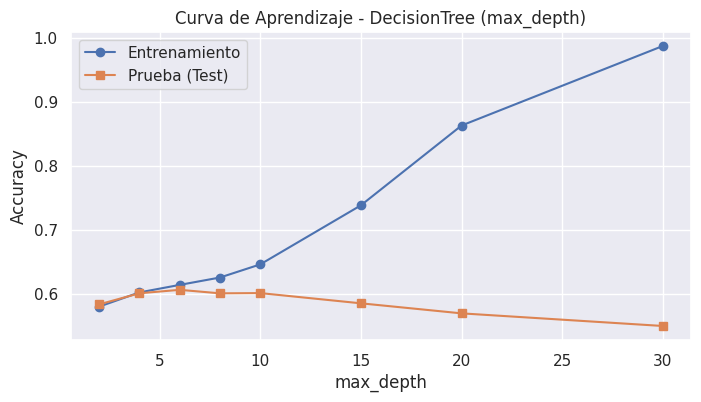

Mejor max_depth: 6 con Accuracy: 0.6067


In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

depths = [2, 4, 6, 8, 10, 15, 20, 30]
train_acc_dt = []
test_acc_dt = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=21)
    dt.fit(X_train, y_train)
    train_acc_dt.append(accuracy_score(y_train, dt.predict(X_train)))
    test_acc_dt.append(accuracy_score(y_test, dt.predict(X_test)))

plt.figure(figsize=(8, 4))
plt.plot(depths, train_acc_dt, label='Entrenamiento', marker='o')
plt.plot(depths, test_acc_dt, label='Prueba (Test)', marker='s')
plt.title('Curva de Aprendizaje - DecisionTree (max_depth)')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()
plt.show()

best_depth = depths[np.argmax(test_acc_dt)]
print(f"Mejor max_depth: {best_depth} con Accuracy: {max(test_acc_dt):.4f}")

# RAMDOM FOREST

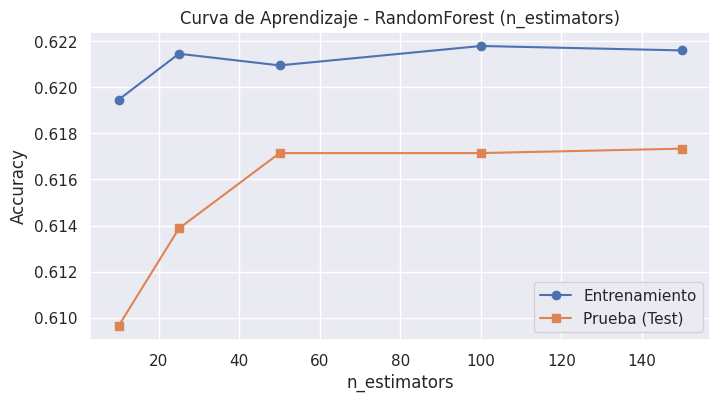

Mejor n_estimators: 150 con Accuracy: 0.6173


In [16]:
from sklearn.ensemble import RandomForestClassifier

estimators = [10, 25, 50, 100, 150]
train_acc_rf = []
test_acc_rf = []

for n in estimators:
    rf = RandomForestClassifier(n_estimators=n, max_depth=best_depth, random_state=21, n_jobs=-1)
    rf.fit(X_train, y_train)
    train_acc_rf.append(accuracy_score(y_train, rf.predict(X_train)))
    test_acc_rf.append(accuracy_score(y_test, rf.predict(X_test)))

plt.figure(figsize=(8, 4))
plt.plot(estimators, train_acc_rf, label='Entrenamiento', marker='o')
plt.plot(estimators, test_acc_rf, label='Prueba (Test)', marker='s')
plt.title('Curva de Aprendizaje - RandomForest (n_estimators)')
plt.xlabel('n_estimators')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()
plt.show()

best_n_est = estimators[np.argmax(test_acc_rf)]
print(f"Mejor n_estimators: {best_n_est} con Accuracy: {max(test_acc_rf):.4f}")

# SUPPORT VECTOR MACHINE

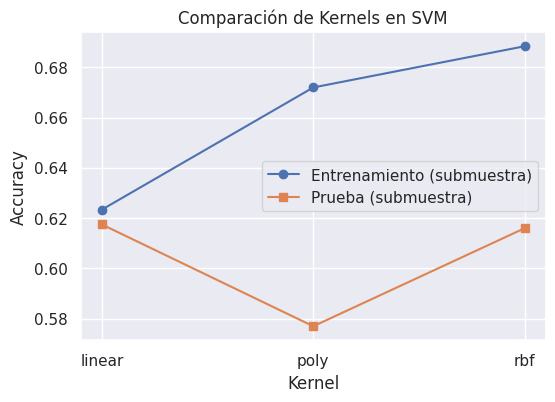

Mejor kernel para SVM: linear


In [17]:
from sklearn.svm import SVC

kernels = ['linear', 'poly', 'rbf']
train_acc_svm = []
test_acc_svm = []

# Muestra estratificada para tuning rápido de SVM
X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train_scaled, y_train, train_size=5000, stratify=y_train, random_state=21
)
X_test_sub, _, y_test_sub, _ = train_test_split(
    X_test_scaled, y_test, train_size=2000, stratify=y_test, random_state=21
)

for k in kernels:
    svm = SVC(kernel=k, random_state=21)
    svm.fit(X_train_sub, y_train_sub)
    train_acc_svm.append(accuracy_score(y_train_sub, svm.predict(X_train_sub)))
    test_acc_svm.append(accuracy_score(y_test_sub, svm.predict(X_test_sub)))

plt.figure(figsize=(6, 4))
plt.plot(kernels, train_acc_svm, label='Entrenamiento (submuestra)', marker='o')
plt.plot(kernels, test_acc_svm, label='Prueba (submuestra)', marker='s')
plt.title('Comparación de Kernels en SVM')
plt.xlabel('Kernel')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()
plt.show()

best_kernel = kernels[np.argmax(test_acc_svm)]
print(f"Mejor kernel para SVM: {best_kernel}")

# CROSS VALIDATION

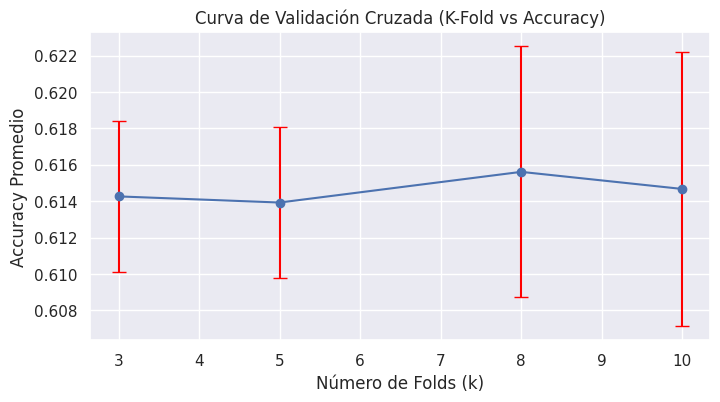

Número óptimo de iteraciones (Folds): 8


In [18]:
from sklearn.model_selection import KFold, cross_val_score

folds_range = [3, 5, 8, 10]
cv_means = []
cv_stds = []

# Evaluamos con el modelo más representativo (RandomForest)
for k in folds_range:
    kf = KFold(n_splits=k, shuffle=True, random_state=21)
    modelo_cv = RandomForestClassifier(n_estimators=best_n_est, max_depth=best_depth, random_state=21, n_jobs=-1)
    scores = cross_val_score(modelo_cv, X_train, y_train, cv=kf, scoring='accuracy')
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

plt.figure(figsize=(8, 4))
plt.errorbar(folds_range, cv_means, yerr=cv_stds, fmt='-o', capsize=5, ecolor='red')
plt.title('Curva de Validación Cruzada (K-Fold vs Accuracy)')
plt.xlabel('Número de Folds (k)')
plt.ylabel('Accuracy Promedio')
plt.grid(True)
plt.show()

best_k = folds_range[np.argmax(cv_means)]
print(f"Número óptimo de iteraciones (Folds): {best_k}")

# DEEP LEARNING

In [19]:
import tensorflow as tf
from tensorflow import keras
tf.keras.utils.set_random_seed(21)

input_dim = X_train_scaled.shape[1]
output_units = num_classes if num_classes > 2 else 1
activation_out = 'softmax' if num_classes > 2 else 'sigmoid'
loss_fn = 'sparse_categorical_crossentropy' if num_classes > 2 else 'binary_crossentropy'

def build_mlp(architecture_type):
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(input_dim,)))

    if architecture_type == 1:
        for units in [64, 128, 128]:
            model.add(keras.layers.Dense(units, activation='relu'))

    elif architecture_type == 2:
        for units in [64, 64, 128, 128, 256, 256]:
            model.add(keras.layers.Dense(units, activation='relu'))

    elif architecture_type == 3:
        for _ in range(10):
            model.add(keras.layers.Dense(128, activation='relu'))

    model.add(keras.layers.Dense(output_units, activation=activation_out))

    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss=loss_fn,
        metrics=['accuracy']
    )
    return model

# EPOCHS

Epochs: 5 -> Test Accuracy: 0.6227
Epochs: 10 -> Test Accuracy: 0.6169
Epochs: 50 -> Test Accuracy: 0.5829
Epochs: 100 -> Test Accuracy: 0.5747


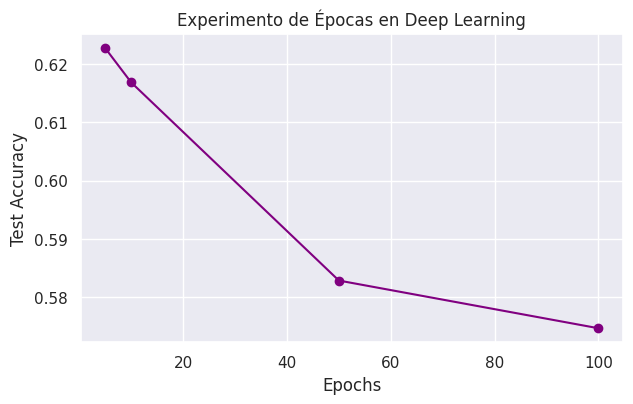

Época seleccionada como óptima: 5


In [20]:
epoch_candidates = [5, 10, 50, 100]
epoch_scores = []

for ep in epoch_candidates:
    modelo_dl_exp = build_mlp(1)
    history = modelo_dl_exp.fit(
        X_train_scaled, y_train,
        epochs=ep,
        batch_size=256,
        validation_split=0.1,
        verbose=0
    )
    test_loss, test_acc = modelo_dl_exp.evaluate(X_test_scaled, y_test, verbose=0)
    epoch_scores.append(test_acc)
    print(f"Epochs: {ep} -> Test Accuracy: {test_acc:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(epoch_candidates, epoch_scores, marker='o', color='purple')
plt.title('Experimento de Épocas en Deep Learning')
plt.xlabel('Epochs')
plt.ylabel('Test Accuracy')
plt.grid(True)
plt.show()

best_epoch = epoch_candidates[np.argmax(epoch_scores)]
print(f"Época seleccionada como óptima: {best_epoch}")

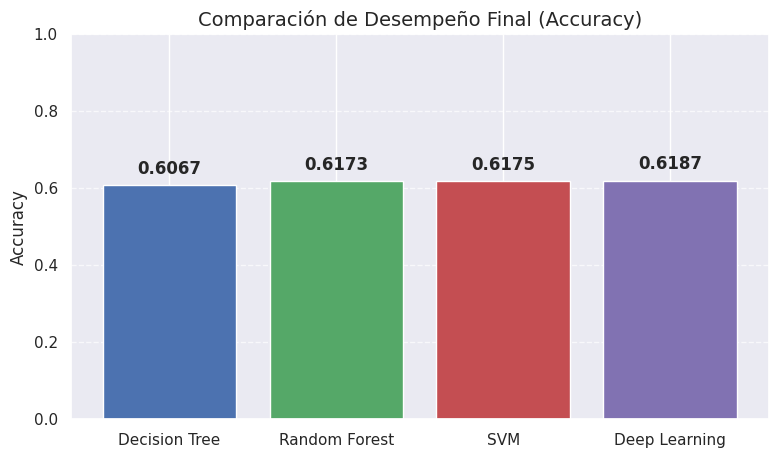

In [21]:
# 1. DecisionTree
dt_final = DecisionTreeClassifier(max_depth=best_depth, random_state=21)
dt_final.fit(X_train, y_train)
acc_dt_final = accuracy_score(y_test, dt_final.predict(X_test))

# 2. RandomForest
rf_final = RandomForestClassifier(n_estimators=best_n_est, max_depth=best_depth, random_state=21, n_jobs=-1)
rf_final.fit(X_train, y_train)
acc_rf_final = accuracy_score(y_test, rf_final.predict(X_test))

# 3. SVM
svm_final = SVC(kernel=best_kernel, random_state=21)
svm_final.fit(X_train_sub, y_train_sub)
acc_svm_final = accuracy_score(y_test_sub, svm_final.predict(X_test_sub))

# 4. Deep Learning
dl_final = build_mlp(1)
dl_final.fit(X_train_scaled, y_train, epochs=best_epoch, batch_size=256, verbose=0)
_, acc_dl_final = dl_final.evaluate(X_test_scaled, y_test, verbose=0)

# Barplot comparativo
modelos = ['Decision Tree', 'Random Forest', 'SVM', 'Deep Learning']
accuracies = [acc_dt_final, acc_rf_final, acc_svm_final, acc_dl_final]

plt.figure(figsize=(9, 5))
bars = plt.bar(modelos, accuracies, color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
plt.ylim(0, 1.0)
plt.title('Comparación de Desempeño Final (Accuracy)', fontsize=14)
plt.ylabel('Accuracy')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# TERCERA PARTE DEL PROYECTO
## Aprendizaje no supervisado: escalado, reducción de dimensionalidad y clustering

## 1. Escalado de los datos (StandardScaler y MinMaxScaler)

In [22]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

np.random.seed(21)

# Dataset limpio (el mismo X de la parte 2) y etiquetas reales solo para comparar
X_full = X.copy()
y_real = np.asarray(y)

# Escalado: StandardScaler (media 0, desviación 1) y MinMaxScaler (rango [0, 1])
X_std = StandardScaler().fit_transform(X_full)
X_mm  = MinMaxScaler().fit_transform(X_full)

print(f"Dataset: {X_full.shape[0]} filas x {X_full.shape[1]} columnas | clases reales: {num_classes}")

resumen_escalado = pd.DataFrame({
    'Original':       [X_full.values.mean(), X_full.values.std(), X_full.values.min(), X_full.values.max()],
    'StandardScaler': [X_std.mean(), X_std.std(), X_std.min(), X_std.max()],
    'MinMaxScaler':   [X_mm.mean(),  X_mm.std(),  X_mm.min(),  X_mm.max()]
}, index=['Media global', 'Desviación global', 'Mínimo', 'Máximo'])
resumen_escalado.round(4)

Dataset: 51963 filas x 29 columnas | clases reales: 3


,Original,StandardScaler,MinMaxScaler
Media global,117.5874,-0.0000,0.4740
Desviación global,578.9907,1.0000,0.3296
Mínimo,0.0000,-132.6459,0.0000
Máximo,5380.0000,107.4539,1.0000


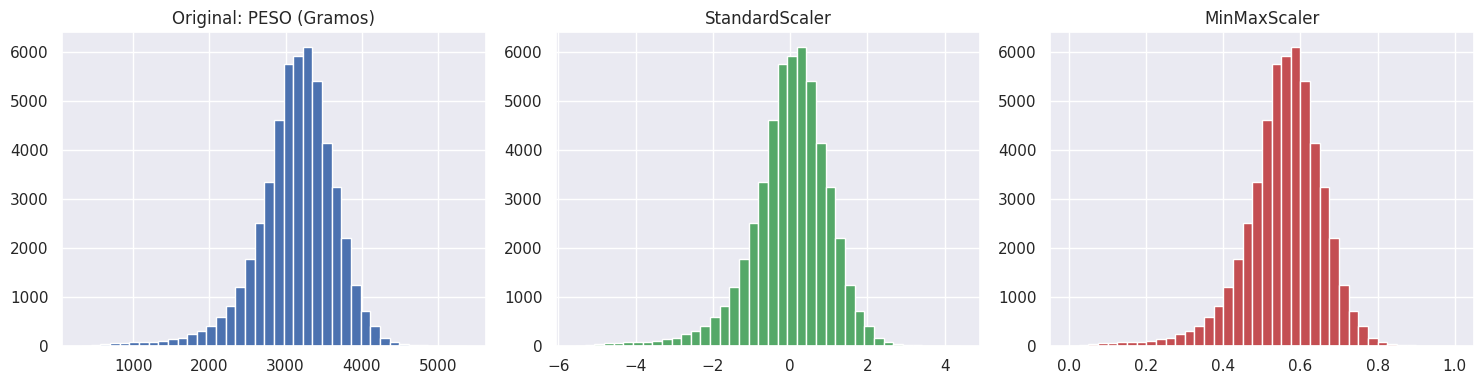

In [23]:
# Efecto del escalado sobre una variable de ejemplo
col_ej = 'PESO (Gramos)' if 'PESO (Gramos)' in X_full.columns else X_full.columns[0]
j = list(X_full.columns).index(col_ej)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(X_full[col_ej], bins=40, color='#4C72B0'); axes[0].set_title(f'Original: {col_ej}')
axes[1].hist(X_std[:, j], bins=40, color='#55A868');    axes[1].set_title('StandardScaler')
axes[2].hist(X_mm[:, j], bins=40, color='#C44E52');     axes[2].set_title('MinMaxScaler')
plt.tight_layout()
plt.show()

## 2. Reducción de dimensionalidad con PCA (N columnas → 2 componentes)

29 columnas -> 2 componentes
StandardScaler | varianza explicada: PC1=0.104, PC2=0.084, total=0.189
MinMaxScaler   | varianza explicada: PC1=0.251, PC2=0.199, total=0.450


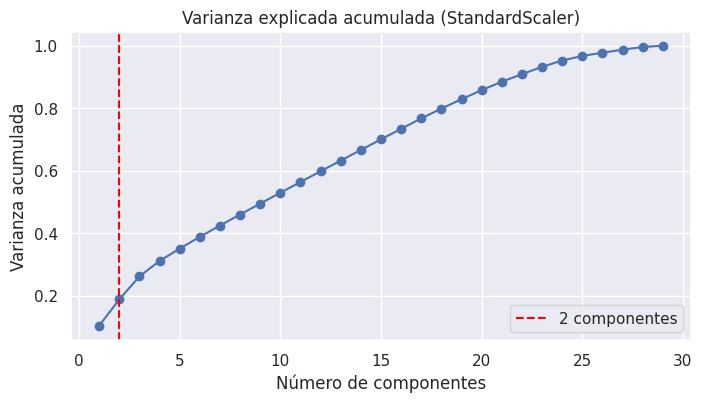

In [24]:
# PCA con ambos escalados
pca_std = PCA(n_components=2, random_state=21)
X_pca_std = pca_std.fit_transform(X_std)

pca_mm = PCA(n_components=2, random_state=21)
X_pca_mm = pca_mm.fit_transform(X_mm)

print(f"{X_full.shape[1]} columnas -> 2 componentes")
print(f"StandardScaler | varianza explicada: PC1={pca_std.explained_variance_ratio_[0]:.3f}, "
      f"PC2={pca_std.explained_variance_ratio_[1]:.3f}, total={pca_std.explained_variance_ratio_.sum():.3f}")
print(f"MinMaxScaler   | varianza explicada: PC1={pca_mm.explained_variance_ratio_[0]:.3f}, "
      f"PC2={pca_mm.explained_variance_ratio_[1]:.3f}, total={pca_mm.explained_variance_ratio_.sum():.3f}")

# Varianza acumulada con todos los componentes (referencia)
pca_full = PCA(random_state=21).fit(X_std)
plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(pca_full.explained_variance_ratio_) + 1),
         np.cumsum(pca_full.explained_variance_ratio_), marker='o')
plt.axvline(2, color='red', linestyle='--', label='2 componentes')
plt.title('Varianza explicada acumulada (StandardScaler)')
plt.xlabel('Número de componentes'); plt.ylabel('Varianza acumulada')
plt.grid(True); plt.legend(); plt.show()

### Opcional: reducción con t-SNE (2 componentes)

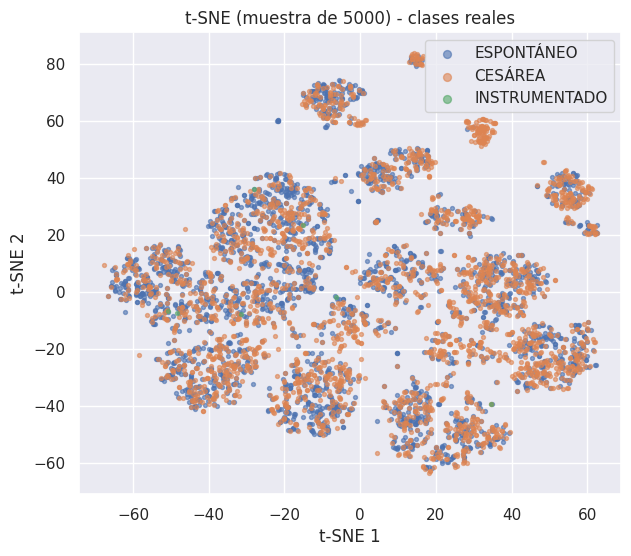

In [25]:
# t-SNE es costoso, se aplica sobre una muestra aleatoria reproducible
n_tsne = min(5000, X_std.shape[0])
rng = np.random.RandomState(21)
idx_tsne = rng.choice(X_std.shape[0], size=n_tsne, replace=False)

tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=21)
X_tsne = tsne.fit_transform(X_std[idx_tsne])
y_tsne = y_real[idx_tsne]

plt.figure(figsize=(7, 6))
for k in range(num_classes):
    m = y_tsne == k
    plt.scatter(X_tsne[m, 0], X_tsne[m, 1], s=8, alpha=0.6, label=str(class_names[k]))
plt.title(f't-SNE (muestra de {n_tsne}) - clases reales')
plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2'); plt.legend(markerscale=2)
plt.show()

## 3. K-Means (n_clusters = número de clases del dataset)

In [26]:
kmeans = KMeans(n_clusters=num_classes, n_init=10, random_state=21)
labels_km = kmeans.fit_predict(X_pca_std)

sil_km = silhouette_score(X_pca_std, labels_km, sample_size=10000, random_state=21)
ari_km = adjusted_rand_score(y_real, labels_km)
nmi_km = normalized_mutual_info_score(y_real, labels_km)

print(f"K-Means (k={num_classes}) | Silhouette={sil_km:.3f} | ARI={ari_km:.3f} | NMI={nmi_km:.3f}")
print("\nTamaño de cada cluster:", {int(k): int(v) for k, v in zip(*np.unique(labels_km, return_counts=True))})

# Cluster vs clase real
pd.crosstab(pd.Series(labels_km, name='Cluster K-Means'),
            pd.Series([class_names[i] for i in y_real], name='Clase real'))

K-Means (k=3) | Silhouette=0.459 | ARI=0.014 | NMI=0.010

Tamaño de cada cluster: {0: 21596, 1: 19524, 2: 10843}


Clase real,CESÁREA,ESPONTÁNEO,INSTRUMENTADO
Cluster K-Means,,,
0,9327,12218,51
1,11403,8093,28
2,5533,5294,16


## 4. DBSCAN

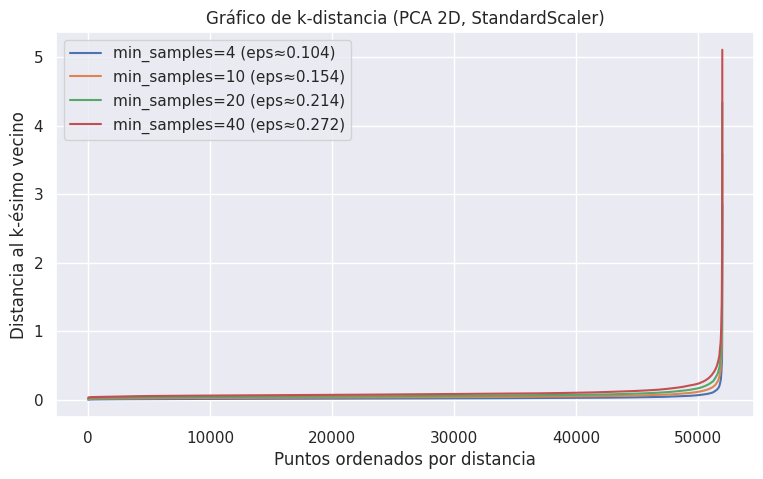

In [27]:
# Búsqueda de eps con el gráfico de k-distancia (distancia al k-ésimo vecino, k = min_samples)
def k_distancias(X, k):
    nn = NearestNeighbors(n_neighbors=k).fit(X)
    dist, _ = nn.kneighbors(X)
    return np.sort(dist[:, -1])

def eps_codo(kd):
    # Punto de la curva más alejado de la recta que une su inicio y su final (codo)
    x = np.linspace(0, 1, len(kd))
    y_n = (kd - kd.min()) / (kd.max() - kd.min() + 1e-12)
    d = np.abs(y_n - x) / np.sqrt(2)
    return kd[np.argmax(d)]

candidatos_ms = [4, 10, 20, 40]
kdists, eps_sugeridos = {}, {}
for ms in candidatos_ms:
    kdists[ms] = k_distancias(X_pca_std, ms)
    eps_sugeridos[ms] = max(eps_codo(kdists[ms]), 1e-3)

plt.figure(figsize=(9, 5))
for ms in candidatos_ms:
    plt.plot(kdists[ms], label=f'min_samples={ms} (eps≈{eps_sugeridos[ms]:.3f})')
plt.title('Gráfico de k-distancia (PCA 2D, StandardScaler)')
plt.xlabel('Puntos ordenados por distancia'); plt.ylabel('Distancia al k-ésimo vecino')
plt.grid(True); plt.legend(); plt.show()

In [28]:
# Evaluación de combinaciones eps / min_samples alrededor del codo
def evaluar_dbscan(X, eps, ms):
    labels = DBSCAN(eps=eps, min_samples=ms, n_jobs=-1).fit_predict(X)
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    ruido = 100 * (~mask).mean()
    # Clusters relevantes: los que contienen al menos 1 % de todos los puntos
    tamanos = np.bincount(labels[mask]) if n_clusters > 0 else np.array([])
    relevantes = np.where(tamanos >= 0.01 * len(X))[0]
    pct_en_relevantes = 100 * tamanos[relevantes].sum() / len(X) if len(relevantes) > 0 else 0
    sil = np.nan
    mask_rel = np.isin(labels, relevantes)
    if len(relevantes) >= 2 and mask_rel.sum() > 10:
        sil = silhouette_score(X[mask_rel], labels[mask_rel],
                               sample_size=min(10000, int(mask_rel.sum())), random_state=21)
    return labels, n_clusters, len(relevantes), ruido, pct_en_relevantes, sil

filas = []
for ms in candidatos_ms:
    for factor in [0.5, 0.75, 1.0, 1.25]:
        eps = eps_sugeridos[ms] * factor
        _, n_c, n_rel, ruido, pct_rel, sil = evaluar_dbscan(X_pca_std, eps, ms)
        filas.append({'min_samples': ms, 'eps': round(eps, 4), 'clusters': n_c, 'clusters relevantes': n_rel,
                      '% ruido': round(ruido, 2), '% puntos en relevantes': round(pct_rel, 2),
                      'silhouette': round(sil, 3) if not np.isnan(sil) else np.nan})

tabla_dbscan = pd.DataFrame(filas)
tabla_dbscan

,min_samples,eps,clusters,clusters relevantes,% ruido,% puntos en relevantes,silhouette
0,4,0.0520,235,1,4.76,91.42,NaN
1,4,0.0780,100,1,2.10,96.51,NaN
2,4,0.1039,53,1,1.17,98.14,NaN
3,4,0.1299,31,1,0.80,98.80,NaN
4,10,0.0770,40,1,6.11,92.61,NaN
5,10,0.1155,12,1,2.78,96.90,NaN
6,10,0.1541,10,1,1.52,98.29,NaN
7,10,0.1926,7,1,0.89,98.97,NaN
8,20,0.1070,12,1,6.95,92.42,NaN
9,20,0.1605,1,1,2.92,97.08,NaN


In [29]:
# Selección: entre 2 y 10 clusters relevantes, ruido <= 15 %, >= 85 % de los puntos en clusters relevantes
# y mayor silhouette
validos = tabla_dbscan[(tabla_dbscan['clusters relevantes'].between(2, 10)) & (tabla_dbscan['% ruido'] <= 15)
                       & (tabla_dbscan['% puntos en relevantes'] >= 85)].dropna(subset=['silhouette'])

if len(validos) > 0:
    mejor = validos.sort_values('silhouette', ascending=False).iloc[0]
    eps_final, ms_final = float(mejor['eps']), int(mejor['min_samples'])
else:
    # Ninguna combinación cumplió el criterio: se usa el codo del gráfico de k-distancia
    ms_final = 10
    eps_final = float(eps_sugeridos[ms_final])

dbscan = DBSCAN(eps=eps_final, min_samples=ms_final, n_jobs=-1)
labels_db = dbscan.fit_predict(X_pca_std)

mask_db = labels_db != -1
n_clusters_db = len(set(labels_db[mask_db]))
ruido_db = 100 * (~mask_db).mean()
sil_db = (silhouette_score(X_pca_std[mask_db], labels_db[mask_db],
                           sample_size=min(10000, int(mask_db.sum())), random_state=21)
          if n_clusters_db >= 2 else np.nan)
ari_db = adjusted_rand_score(y_real, labels_db)
nmi_db = normalized_mutual_info_score(y_real, labels_db)

print(f"DBSCAN final: eps={eps_final:.4f}, min_samples={ms_final}")
print(f"Clusters: {n_clusters_db} | Ruido: {ruido_db:.2f}% | Silhouette={sil_db:.3f} | ARI={ari_db:.3f} | NMI={nmi_db:.3f}")
tam_db = pd.Series(labels_db).value_counts()
print("Tamaño de los clusters más grandes (-1 = ruido):")
print(tam_db.head(10).to_string())

DBSCAN final: eps=0.1541, min_samples=10
Clusters: 10 | Ruido: 1.52% | Silhouette=0.236 | ARI=0.000 | NMI=0.000
Tamaño de los clusters más grandes (-1 = ruido):
 0    51072
-1      788
 1       20
 3       18
 7       12
 2       10
 4       10
 5       10
 6       10
 8        7


## 5. Gráficas de resultados: Original, K-Means y DBSCAN

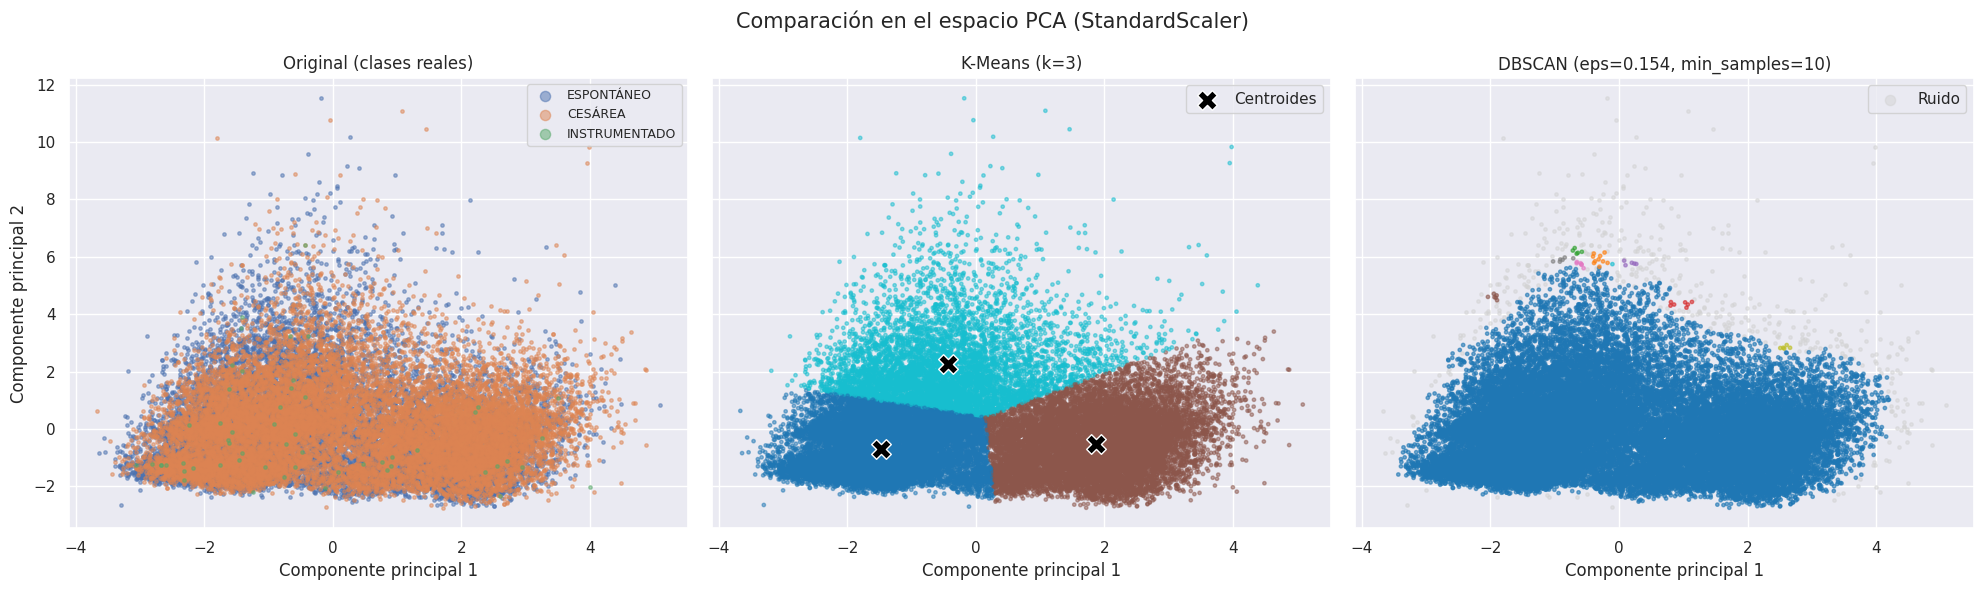

In [30]:
# Para graficar de forma legible se usa una muestra si el dataset es muy grande
n_plot = min(30000, X_pca_std.shape[0])
idx_plot = np.random.RandomState(21).choice(X_pca_std.shape[0], size=n_plot, replace=False)
P = X_pca_std[idx_plot]

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)

# 1) Original: clases reales
for k in range(num_classes):
    m = y_real[idx_plot] == k
    axes[0].scatter(P[m, 0], P[m, 1], s=6, alpha=0.5, label=str(class_names[k]))
axes[0].set_title('Original (clases reales)')
axes[0].legend(markerscale=3, fontsize=9)

# 2) K-Means
sc = axes[1].scatter(P[:, 0], P[:, 1], c=labels_km[idx_plot], cmap='tab10', s=6, alpha=0.5)
axes[1].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
                c='black', marker='X', s=200, edgecolor='white', label='Centroides')
axes[1].set_title(f'K-Means (k={num_classes})')
axes[1].legend()

# 3) DBSCAN (ruido en gris)
lab_p = labels_db[idx_plot]
ruido_m = lab_p == -1
axes[2].scatter(P[ruido_m, 0], P[ruido_m, 1], c='lightgray', s=6, alpha=0.5, label='Ruido')
axes[2].scatter(P[~ruido_m, 0], P[~ruido_m, 1], c=lab_p[~ruido_m], cmap='tab10', s=6, alpha=0.6)
axes[2].set_title(f'DBSCAN (eps={eps_final:.3f}, min_samples={ms_final})')
axes[2].legend(markerscale=3)

for ax in axes:
    ax.set_xlabel('Componente principal 1')
axes[0].set_ylabel('Componente principal 2')
plt.suptitle('Comparación en el espacio PCA (StandardScaler)', fontsize=15)
plt.tight_layout()
plt.show()

In [31]:
# Tabla resumen de métricas
resumen_final = pd.DataFrame({
    'Método': ['K-Means', 'DBSCAN'],
    'Clusters': [num_classes, n_clusters_db],
    '% Ruido': [0.0, round(ruido_db, 2)],
    'Silhouette': [round(sil_km, 3), round(sil_db, 3) if not np.isnan(sil_db) else np.nan],
    'ARI (vs clases reales)': [round(ari_km, 3), round(ari_db, 3)],
    'NMI (vs clases reales)': [round(nmi_km, 3), round(nmi_db, 3)]
})
resumen_final

,Método,Clusters,% Ruido,Silhouette,ARI (vs clases reales),NMI (vs clases reales)
0,K-Means,3,0.00,0.459,0.014,0.01
1,DBSCAN,10,1.52,0.236,0.000,0.00
